# Remaining useful life on all four C-MAPSS subsets

Notebook 1 covered FD001, the easiest subset. This one asks three harder questions:

1. **Does the same approach hold on FD002 to FD004**, which add six operating conditions and a second fault mode?
2. **How much does normalising per operating condition matter?**
3. **Does a model trained on one subset work on another?**

| Subset | Operating conditions | Fault modes |
|---|---|---|
| FD001 | 1 | 1 (HPC) |
| FD002 | 6 | 1 (HPC) |
| FD003 | 1 | 2 (HPC, fan) |
| FD004 | 6 | 2 (HPC, fan) |

Runtime: roughly 15 to 20 minutes on CPU; a GPU is used automatically if present.

## 1. Setup

In [1]:
import os, subprocess, time
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

SEED = 42
SUBSETS = ["FD001", "FD002", "FD003", "FD004"]
RUL_CAP = 125
WINDOW = 30
VAL_FRACTION = 0.2
SEEDS = [0, 1, 2]
MAX_EPOCHS = int(os.environ.get("MAX_EPOCHS", 40))
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# The 14 sensors that vary in FD001 (see notebook 1); used for every subset so models are comparable.
SENSORS = ["s2", "s3", "s4", "s7", "s8", "s9", "s11", "s12", "s13", "s14", "s15", "s17", "s20", "s21"]
SETTINGS = ["setting_1", "setting_2", "setting_3"]
COLS = ["unit", "cycle"] + SETTINGS + [f"s{i}" for i in range(1, 22)]

DATA_DIR = Path("CMAPSSData")
if not (DATA_DIR / "train_FD001.txt").exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/edwardzjl/CMAPSSData", str(DATA_DIR)], check=True)
print("torch", torch.__version__, "| device:", DEVICE)

torch 2.15.0+cu132 | device: cpu


## 2. Load the data and find the operating conditions

The three settings columns (altitude, Mach number, throttle angle) take a handful of distinct values once rounded. Each distinct combination is one operating condition.

In [2]:
def load_subset(fd):
    read = lambda name: pd.read_csv(DATA_DIR / name, sep=r"\s+", header=None, names=COLS)
    train, test = read(f"train_{fd}.txt"), read(f"test_{fd}.txt")
    rul = pd.read_csv(DATA_DIR / f"RUL_{fd}.txt", header=None)[0].to_numpy()
    for df in (train, test):
        # Round away the simulator's jitter so each flight regime gets one label.
        df["condition"] = (df["setting_1"].round(0).astype(int).astype(str) + "_"
                           + (df["setting_2"].round(2) + 0.0).astype(str) + "_"   # + 0.0 turns -0.0 into 0.0
                           + df["setting_3"].round(0).astype(int).astype(str))
    train["rul"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]
    train["y"] = train["rul"].clip(upper=RUL_CAP)
    return train, test, rul

raw = {fd: load_subset(fd) for fd in SUBSETS}
summary = pd.DataFrame([{
    "subset": fd, "train engines": tr.unit.nunique(), "train rows": len(tr),
    "test engines": te.unit.nunique(), "conditions": tr.condition.nunique(),
    "shortest test history": int(te.groupby("unit").size().min()),
    "median true test RUL": int(np.median(rul)),
} for fd, (tr, te, rul) in raw.items()])
summary

,subset,train engines,train rows,test engines,conditions,shortest test history,median true test RUL
0,FD001,100,20631,100,1,31,86
1,FD002,260,53759,259,6,21,80
2,FD003,100,24720,100,1,38,77
3,FD004,249,61249,248,6,19,88


In FD002 and FD004 the raw sensors mostly reflect the flight regime, not engine health. One sensor in one FD002 engine, coloured by condition:

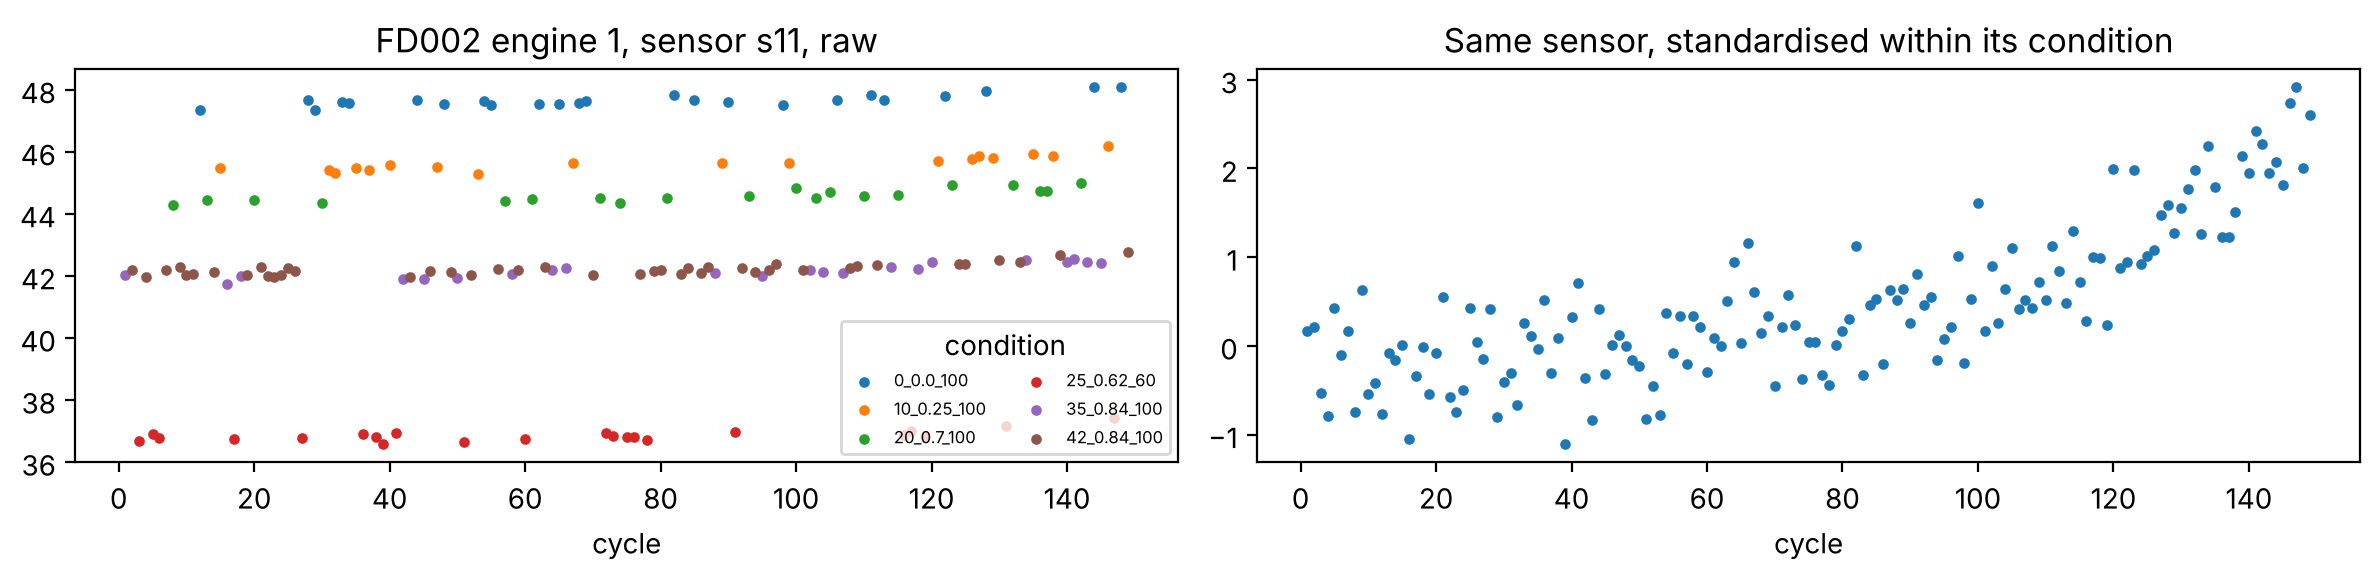

In [3]:
tr2 = raw["FD002"][0]
g = tr2[tr2.unit == 1]
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
for cond, part in g.groupby("condition"):
    ax[0].scatter(part.cycle, part.s11, s=8, label=cond)
ax[0].set_title("FD002 engine 1, sensor s11, raw"); ax[0].set_xlabel("cycle"); ax[0].legend(fontsize=6, ncol=2, title="condition")
stats = tr2.groupby("condition")["s11"].agg(["mean", "std"])
z = (g.s11 - g.condition.map(stats["mean"])) / g.condition.map(stats["std"])
ax[1].scatter(g.cycle, z, s=8, color="tab:blue")
ax[1].set_title("Same sensor, standardised within its condition"); ax[1].set_xlabel("cycle")
plt.tight_layout(); plt.show()

Raw, the sensor jumps between six bands and the degradation trend is invisible. Standardised within each condition, the upward drift toward failure appears. That is the reason for per-condition normalisation.

## 3. Split and scaling

- **Split by engine**, as in notebook 1: 20% of training engines are held out for validation.
- **Scaling** is fitted on the training engines only, in one of two modes:
  - `condition`: mean and standard deviation per operating condition.
  - `global`: one mean and standard deviation for the whole subset.
- A condition never seen when fitting falls back to the global statistics. This matters in section 7.

In [4]:
class Scaler:
    def __init__(self, mode="condition"):
        self.mode = mode

    def fit(self, df):
        self.g_mean, self.g_std = df[SENSORS].mean(), df[SENSORS].std().replace(0, 1)
        if self.mode == "condition":
            grouped = df.groupby("condition")[SENSORS]
            self.c_mean, self.c_std = grouped.mean(), grouped.std().fillna(0)
            # A sensor that is constant within a condition carries no signal there: scale by 1 so it becomes 0.
            self.c_std = self.c_std.where(self.c_std > 1e-8, 1.0)
        return self

    def transform(self, df):
        out = df.copy()
        values = (df[SENSORS] - self.g_mean) / self.g_std
        if self.mode == "condition":
            known = df["condition"].isin(self.c_mean.index)
            if known.any():
                part = df.loc[known]
                m = self.c_mean.loc[part["condition"]].to_numpy()
                s = self.c_std.loc[part["condition"]].to_numpy()
                values.loc[known] = (part[SENSORS].to_numpy() - m) / s
            self.unseen_share_ = float(1 - known.mean())
        out[SENSORS] = values.astype("float32")
        return out

def split_engines(train, seed=SEED):
    units = np.random.default_rng(seed).permutation(train["unit"].unique())
    val_units = set(units[: int(round(VAL_FRACTION * len(units)))])
    return train[~train.unit.isin(val_units)], train[train.unit.isin(val_units)]

def prepare(fd, mode="condition"):
    train, test, rul = raw[fd]
    tr, va = split_engines(train)
    assert not set(tr.unit) & set(va.unit)
    scaler = Scaler(mode).fit(tr)
    return {"fd": fd, "scaler": scaler, "train": scaler.transform(tr), "val": scaler.transform(va),
            "test": scaler.transform(test), "rul": rul}

## 4. Metrics, windows and models

Same definitions as notebook 1, wrapped in functions so they can be reused across subsets.

In [5]:
def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))

def nasa_score(y, p):
    d = np.asarray(p) - np.asarray(y)          # positive = predicted too late
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

def test_metrics(rul, pred):
    return {"rmse_capped": rmse(np.minimum(rul, RUL_CAP), pred), "rmse_true": rmse(rul, pred),
            "nasa": nasa_score(rul, pred), "nasa_per_engine": nasa_score(rul, pred) / len(rul)}

def pad_front(a):
    if len(a) < WINDOW:
        a = np.vstack([np.repeat(a[:1], WINDOW - len(a), axis=0), a])
    return a

def all_windows(df):
    X, y = [], []
    for _, g in df.groupby("unit"):
        a = pad_front(g[SENSORS].to_numpy(np.float32))
        target, offset = g["y"].to_numpy(np.float32), max(0, WINDOW - len(g))
        for end in range(WINDOW, len(a) + 1):
            X.append(a[end - WINDOW:end]); y.append(target[end - 1 - offset])
    return np.stack(X), np.array(y, np.float32)

def last_windows(df):
    return np.stack([pad_front(g[SENSORS].to_numpy(np.float32))[-WINDOW:] for _, g in df.groupby("unit")])

class RULNet(nn.Module):
    def __init__(self, n_features, hidden=64):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, num_layers=2, batch_first=True, dropout=0.2)
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1]).squeeze(-1)

def predict(model, X, batch=4096):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            xb = torch.as_tensor(X[i:i + batch]).to(DEVICE)
            out.append((model(xb) * RUL_CAP).clamp(0, RUL_CAP).cpu().numpy())
    return np.concatenate(out)

def train_lstm(Xtr, ytr, Xva, yva, seed, max_epochs=MAX_EPOCHS, patience=6, batch=256, lr=1e-3):
    torch.manual_seed(seed)
    model = RULNet(Xtr.shape[2]).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    X, y = torch.as_tensor(Xtr).to(DEVICE), (torch.as_tensor(ytr) / RUL_CAP).to(DEVICE)
    best, best_state, bad, history = np.inf, None, 0, []
    for epoch in range(max_epochs):
        model.train()
        order, total = torch.randperm(len(X), device=DEVICE), 0.0
        for i in range(0, len(X), batch):
            idx = order[i:i + batch]
            opt.zero_grad()
            loss = loss_fn(model(X[idx]), y[idx])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            total += loss.item() * len(idx)
        val_rmse = rmse(yva, predict(model, Xva))
        history.append((total / len(X), val_rmse))
        if val_rmse < best - 1e-3:
            best, bad = val_rmse, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    return model, best, history

def rolling_features(df):
    g = df.groupby("unit")[SENSORS]
    mean = g.rolling(WINDOW, min_periods=1).mean().reset_index(level=0, drop=True).add_suffix("_mean")
    std = g.rolling(WINDOW, min_periods=2).std().reset_index(level=0, drop=True).fillna(0).add_suffix("_std")
    return pd.concat([df[SENSORS], mean, std], axis=1)

LGB_PARAMS = dict(n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=40,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)

def run_lightgbm(data):
    model = lgb.LGBMRegressor(**LGB_PARAMS).fit(rolling_features(data["train"]), data["train"]["y"])
    last = data["test"].groupby("unit")["cycle"].idxmax().to_numpy()
    pred = np.clip(model.predict(rolling_features(data["test"]).loc[last]), 0, RUL_CAP)
    val = rmse(data["val"]["y"], np.clip(model.predict(rolling_features(data["val"])), 0, RUL_CAP))
    return {"val_rmse": val, **test_metrics(data["rul"], pred)}

def run_lstm(data, seeds=SEEDS, label=""):
    Xtr, ytr = all_windows(data["train"]); Xva, yva = all_windows(data["val"]); Xte = last_windows(data["test"])
    runs = []
    for seed in seeds:
        t0 = time.time()
        model, val, history = train_lstm(Xtr, ytr, Xva, yva, seed)
        pred = predict(model, Xte)
        runs.append({"seed": seed, "model": model, "pred": pred, "val_rmse": val, "history": history,
                     **test_metrics(data["rul"], pred)})
        print(f"{label} seed {seed}: {len(history):2d} epochs, train MSE {history[0][0]:.4f} -> {history[-1][0]:.4f}, "
              f"val RMSE {val:.2f}, test RMSE {runs[-1]['rmse_capped']:.2f} (capped)  [{time.time() - t0:.0f}s]")
    return runs

## 5. All four subsets, per-condition scaling

LightGBM on rolling features and the LSTM (3 seeds), each trained and tested within its own subset.

In [6]:
data = {fd: prepare(fd, "condition") for fd in SUBSETS}
gbm_results = {fd: run_lightgbm(data[fd]) for fd in SUBSETS}
lstm_runs = {fd: run_lstm(data[fd], label=fd) for fd in SUBSETS}

FD001 seed 0: 14 epochs, train MSE 0.1731 -> 0.0088, val RMSE 13.70, test RMSE 14.34 (capped)  [23s]


FD001 seed 1: 12 epochs, train MSE 0.0921 -> 0.0087, val RMSE 14.27, test RMSE 14.20 (capped)  [18s]


FD001 seed 2: 13 epochs, train MSE 0.2132 -> 0.0085, val RMSE 13.72, test RMSE 14.65 (capped)  [19s]


FD002 seed 0: 15 epochs, train MSE 0.0822 -> 0.0099, val RMSE 15.17, test RMSE 14.10 (capped)  [56s]


FD002 seed 1: 17 epochs, train MSE 0.0509 -> 0.0088, val RMSE 15.34, test RMSE 14.59 (capped)  [61s]


FD002 seed 2: 13 epochs, train MSE 0.0981 -> 0.0101, val RMSE 15.22, test RMSE 14.18 (capped)  [45s]


... (2 outputs left out)

FD003 seed 2: 13 epochs, train MSE 0.1984 -> 0.0070, val RMSE 11.60, test RMSE 14.62 (capped)  [23s]


FD004 seed 0: 17 epochs, train MSE 0.0806 -> 0.0088, val RMSE 15.57, test RMSE 14.40 (capped)  [71s]


FD004 seed 1: 12 epochs, train MSE 0.0503 -> 0.0103, val RMSE 15.71, test RMSE 14.15 (capped)  [51s]


FD004 seed 2: 12 epochs, train MSE 0.0971 -> 0.0094, val RMSE 15.82, test RMSE 15.01 (capped)  [51s]


In [7]:
def summarise(runs):
    df = pd.DataFrame([{k: r[k] for k in ("val_rmse", "rmse_capped", "rmse_true", "nasa", "nasa_per_engine")} for r in runs])
    return df.mean(), df.std()

rows = []
for fd in SUBSETS:
    g = gbm_results[fd]
    mean, std = summarise(lstm_runs[fd])
    rows.append({"subset": fd, "test engines": len(data[fd]["rul"]),
                 "LightGBM RMSE": g["rmse_capped"], "LSTM RMSE": mean.rmse_capped, "LSTM RMSE std": std.rmse_capped,
                 "LSTM RMSE (true RUL)": mean.rmse_true,
                 "LightGBM NASA/engine": g["nasa_per_engine"], "LSTM NASA/engine": mean.nasa_per_engine,
                 "LSTM NASA score": mean.nasa})
within = pd.DataFrame(rows)
within.round(2)

,subset,test engines,LightGBM RMSE,LSTM RMSE,LSTM RMSE std,LSTM RMSE (true RUL),LightGBM NASA/engine,LSTM NASA/engine,LSTM NASA score
0,FD001,100,15.88,14.40,0.23,15.79,6.75,4.20,420.36
1,FD002,259,15.78,14.29,0.26,26.76,68.38,33.54,8687.00
2,FD003,100,17.37,14.65,0.59,16.05,11.46,7.52,751.53
3,FD004,248,18.01,14.52,0.44,26.95,26.41,21.13,5239.12


RMSE columns use the capped truth unless marked. Against the uncapped truth the error is much larger on FD002 and FD004, because many of their test engines have more than 125 cycles left and the model cannot predict above the cap. The NASA score is a sum over engines, so subsets with more test engines score higher by construction; the per-engine column is the one to compare across subsets.

## 6. How much does per-condition scaling matter?

Same models on FD002 and FD004, but with one global mean and standard deviation instead of one per condition.

In [8]:
ablation = []
for fd in ["FD002", "FD004"]:
    d_global = prepare(fd, "global")
    g = run_lightgbm(d_global)
    runs = run_lstm(d_global, label=f"{fd} global")
    mean, std = summarise(runs)
    cond_mean, cond_std = summarise(lstm_runs[fd])
    ablation.append({"subset": fd,
                     "LightGBM, global": g["rmse_capped"], "LightGBM, per condition": gbm_results[fd]["rmse_capped"],
                     "LSTM, global": mean.rmse_capped, "LSTM global std": std.rmse_capped,
                     "LSTM, per condition": cond_mean.rmse_capped, "LSTM per-condition std": cond_std.rmse_capped})
pd.DataFrame(ablation).round(2)

FD002 global seed 0: 18 epochs, train MSE 0.1222 -> 0.0171, val RMSE 17.35, test RMSE 16.38 (capped)  [68s]


FD002 global seed 1: 28 epochs, train MSE 0.0901 -> 0.0134, val RMSE 16.89, test RMSE 16.56 (capped)  [109s]


FD002 global seed 2: 20 epochs, train MSE 0.1600 -> 0.0167, val RMSE 17.30, test RMSE 15.81 (capped)  [77s]


FD004 global seed 0: 25 epochs, train MSE 0.1196 -> 0.0158, val RMSE 19.01, test RMSE 19.24 (capped)  [115s]


FD004 global seed 1: 14 epochs, train MSE 0.0874 -> 0.0172, val RMSE 19.38, test RMSE 19.32 (capped)  [68s]


FD004 global seed 2: 17 epochs, train MSE 0.1566 -> 0.0176, val RMSE 19.13, test RMSE 19.27 (capped)  [80s]


,subset,"LightGBM, global","LightGBM, per condition","LSTM, global",LSTM global std,"LSTM, per condition",LSTM per-condition std
0,FD002,17.31,15.78,16.25,0.39,14.29,0.26
1,FD004,19.63,18.01,19.28,0.04,14.52,0.44


## 7. Train on one subset, test on another

Each LSTM from section 5 is applied to the test engines of every subset, with no retraining. The target subset's sensors are scaled with the **source** subset's statistics, because in deployment that is all the model would have. Operating conditions the source never saw fall back to its global statistics.

Rows are the training subset, columns the test subset. Values are test RMSE in cycles (capped truth), averaged over seeds.

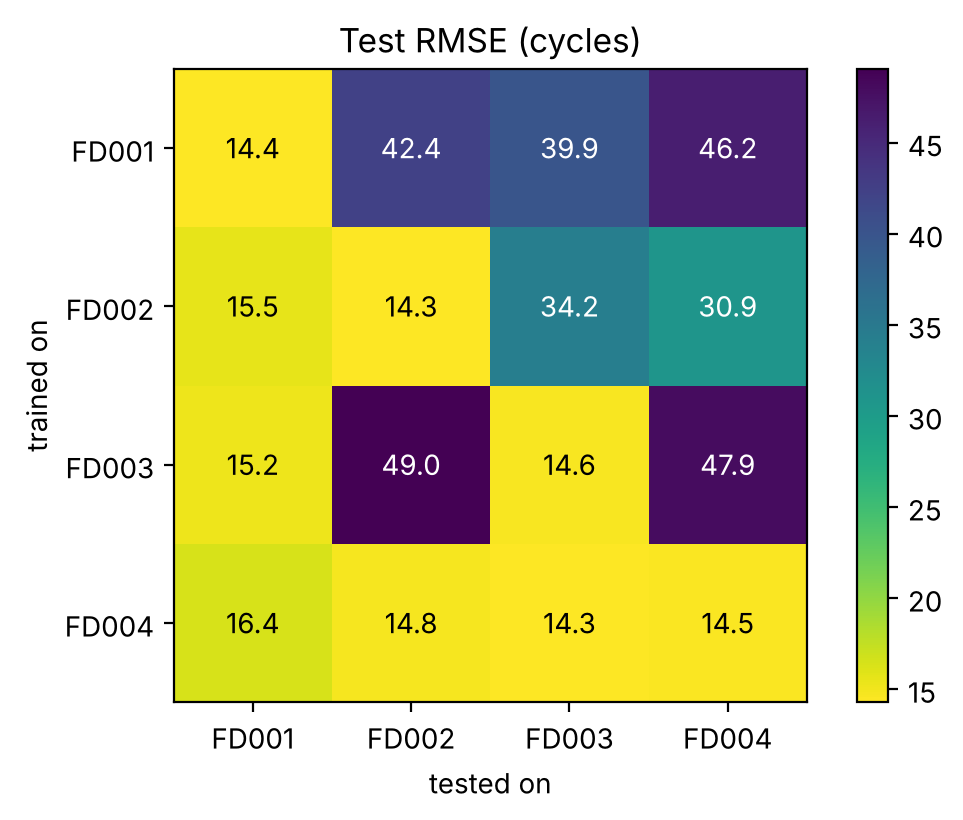

Share of target test rows in operating conditions the source never saw:


,FD001,FD002,FD003,FD004
FD001,0.0,0.85,0.0,0.85
FD002,0.0,0.00,0.0,0.00
FD003,0.0,0.85,0.0,0.85
FD004,0.0,0.00,0.0,0.00


In [9]:
transfer = pd.DataFrame(index=SUBSETS, columns=SUBSETS, dtype=float)
unseen = pd.DataFrame(index=SUBSETS, columns=SUBSETS, dtype=float)
for src in SUBSETS:
    scaler = data[src]["scaler"]
    for tgt in SUBSETS:
        test_scaled = scaler.transform(raw[tgt][1])
        unseen.loc[src, tgt] = scaler.unseen_share_
        X = last_windows(test_scaled)
        rul = raw[tgt][2]
        transfer.loc[src, tgt] = np.mean([rmse(np.minimum(rul, RUL_CAP), predict(r["model"], X)) for r in lstm_runs[src]])

fig, ax = plt.subplots(figsize=(5.6, 4.2))
im = ax.imshow(transfer.to_numpy(float), cmap="viridis_r")
ax.set_xticks(range(4)); ax.set_xticklabels(SUBSETS); ax.set_yticks(range(4)); ax.set_yticklabels(SUBSETS)
ax.set_xlabel("tested on"); ax.set_ylabel("trained on"); ax.set_title("Test RMSE (cycles)")
for i in range(4):
    for j in range(4):
        v = transfer.iloc[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", color="white" if v > transfer.to_numpy(float).mean() else "black")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

print("Share of target test rows in operating conditions the source never saw:")
unseen.round(2)

In [10]:
# For reference: what a model that knows nothing would score on each test set (predicting the cap, or the training mean).
ref = pd.DataFrame([{"subset": fd,
                     "always predict the training mean": rmse(np.minimum(raw[fd][2], RUL_CAP), np.full(len(raw[fd][2]), data[fd]["train"]["y"].mean()))}
                    for fd in SUBSETS]).set_index("subset").T
ref.round(1)

subset,FD001,FD002,FD003,FD004
always predict the training mean,42.1,44.9,43.9,45.5


## 8. Results in one place

In [11]:
print("Within-subset (section 5):")
display(within.round(2))
print("Scaling ablation (section 6):")
display(pd.DataFrame(ablation).round(2))
print("Transfer, trained on row / tested on column (section 7):")
display(transfer.round(1))

Within-subset (section 5):


,subset,test engines,LightGBM RMSE,LSTM RMSE,LSTM RMSE std,LSTM RMSE (true RUL),LightGBM NASA/engine,LSTM NASA/engine,LSTM NASA score
0,FD001,100,15.88,14.40,0.23,15.79,6.75,4.20,420.36
1,FD002,259,15.78,14.29,0.26,26.76,68.38,33.54,8687.00
2,FD003,100,17.37,14.65,0.59,16.05,11.46,7.52,751.53
3,FD004,248,18.01,14.52,0.44,26.95,26.41,21.13,5239.12


Scaling ablation (section 6):


,subset,"LightGBM, global","LightGBM, per condition","LSTM, global",LSTM global std,"LSTM, per condition",LSTM per-condition std
0,FD002,17.31,15.78,16.25,0.39,14.29,0.26
1,FD004,19.63,18.01,19.28,0.04,14.52,0.44


Transfer, trained on row / tested on column (section 7):


,FD001,FD002,FD003,FD004
FD001,14.4,42.4,39.9,46.2
FD002,15.5,14.3,34.2,30.9
FD003,15.2,49.0,14.6,47.9
FD004,16.4,14.8,14.3,14.5


## 9. What the results show

- **The approach holds on all four subsets.** With per-condition scaling, the LSTM's capped-truth error on FD002 to FD004 is about the same as on FD001, and it beats LightGBM on every subset.
- **Per-condition scaling matters, more for the harder subset.** With one global scaler the LSTM is clearly worse on FD002 and much worse on FD004.
- **Transfer works only onto ground the model has covered.** The FD004 model (six conditions, two fault modes) scores on every other test set about as well as the models trained there. Models trained on one condition fail on six-condition data, and models trained on one fault mode fail where a second one is present; several of those cells are no better than always predicting the training mean (section 7's reference row).
- **A hypothesis, not tested here:** the second fault mode (fan degradation) moves some sensors in a different direction from HPC degradation, which would explain why FD001 to FD003 fails even though the operating condition is the same.

## 10. Limitations

- **Three seeds per configuration.** Enough to see large effects, not to separate models that differ by a cycle.
- **Operating conditions are identified by rounding the settings.** This works because the simulator uses six fixed regimes. Real fleets vary continuously and would need clustering or a model that takes the settings as inputs.
- **Transfer uses source statistics for the target.** A fleet operator could re-fit the scaling on unlabelled target data (no failures needed), which would likely narrow the gap. That is not tested here.
- **Same architecture and hyperparameters everywhere.** Nothing was tuned per subset.
- **Simulated data**, as in notebook 1.

## 11. Next steps

1. Track these runs with MLflow.
2. Add an anomaly detector for leaving the healthy regime.
3. Serve the model with FastAPI and package it with Docker.